# 05 · The polls themselves

Part 1 of the study plan (`docs/study_plan.md`): what the polls look like before comparing them with the results.
Built block by block: **coverage**, then trajectories, rank stability, pollsters and noise.

Input: `data/final/polls.csv` (notebook 04). Tables go to `results/tables/`, figures to `results/figures/`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from polls import average, figures, ideology, metrics, timeline

pd.set_option("display.width", 200)
TABLES, FIGURES = ROOT / "results" / "tables", ROOT / "results" / "figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

calendar = timeline.load(ROOT / "config" / "elections.yaml")
rows = timeline.add_time(pd.read_csv(ROOT / "data" / "final" / "polls.csv", low_memory=False), calendar)
ELECTIONS = sorted(rows["election"].unique())

## 1 · Coverage

One row per poll: when, by whom, how big, how many scenarios, and its ballot scenario if it has one.

In [2]:
tested = rows[rows["share_status"] != "not_tested"]
ballot = tested[tested["ballot_scenario"]]
polls = rows.drop_duplicates("poll_id")[["election", "poll_id", "institute", "institute_family", "sponsor", "date",
                                          "days_before", "weeks_before", "phase", "rolling", "sample_size"]].copy()
polls["n_scenarios"] = polls["poll_id"].map(rows.groupby("poll_id")["scenario_id"].nunique())
polls["has_ballot_scenario"] = polls["poll_id"].isin(ballot["poll_id"])
polls["n_candidates_ballot"] = polls["poll_id"].map(ballot.groupby("poll_id")["candidate"].nunique())
polls["rolling"] = polls["rolling"].fillna(False).astype(bool)

by_election = polls.groupby("election").agg(
    polls=("poll_id", "size"), pollsters=("institute_family", "nunique"),
    first_poll=("date", "min"), last_poll=("date", "max"),
    days_before_first=("days_before", "max"), days_before_last=("days_before", "min"),
    with_ballot_scenario=("has_ballot_scenario", "sum"), rolling=("rolling", "sum"),
    multi_scenario=("n_scenarios", lambda x: int((x > 1).sum())))
phases = pd.crosstab(polls["election"], polls["phase"])
coverage = by_election.join(phases)
coverage.to_csv(TABLES / "coverage_by_election.csv")
coverage

,polls,pollsters,first_poll,last_poll,days_before_first,days_before_last,with_ballot_scenario,rolling,multi_scenario,before the official list,official list to two weeks before,last two weeks
election,,,,,,,,,,,,
2002,98,6,1999-05-07,2002-04-18,1080,3,49,0,0,81,5,12
2007,107,6,2005-01-21,2007-04-20,821,2,107,0,1,69,20,18
2012,124,8,2007-11-02,2012-04-17,1633,5,116,0,19,95,17,12
2017,148,12,2012-10-12,2017-04-21,1654,2,109,0,66,103,23,22
2022,231,11,2017-10-18,2022-04-08,1635,2,184,32,76,161,37,33


### Polls per pollster

Pollster families (Sofres, TNS Sofres, Kantar → one family).

In [3]:
by_pollster = pd.crosstab(polls["institute_family"], polls["election"], margins=True, margins_name="all")
by_pollster = by_pollster.sort_values("all", ascending=False)
by_pollster.to_csv(TABLES / "coverage_by_pollster.csv")
by_pollster

election,2002,2007,2012,2017,2022,all
institute_family,,,,,,
all,98,107,124,148,231,708
Ifop,16,22,37,40,42,157
Ipsos,21,25,20,17,25,108
OpinionWay,0,0,15,13,51,79
Harris Interactive,0,0,12,11,44,67
BVA,10,11,12,20,13,66
Kantar (Sofres),23,17,6,11,4,61
CSA,23,20,13,2,0,58
Elabe,0,0,0,18,25,43


### Pace: polls per week before the vote

The last 52 weeks. Week 1 is the last seven days before the first round.

share of each election's polls in the last 4 and 8 weeks:


,4,8
election,,
2002,0.24,0.44
2007,0.30,0.55
2012,0.20,0.38
2017,0.26,0.43
2022,0.26,0.43


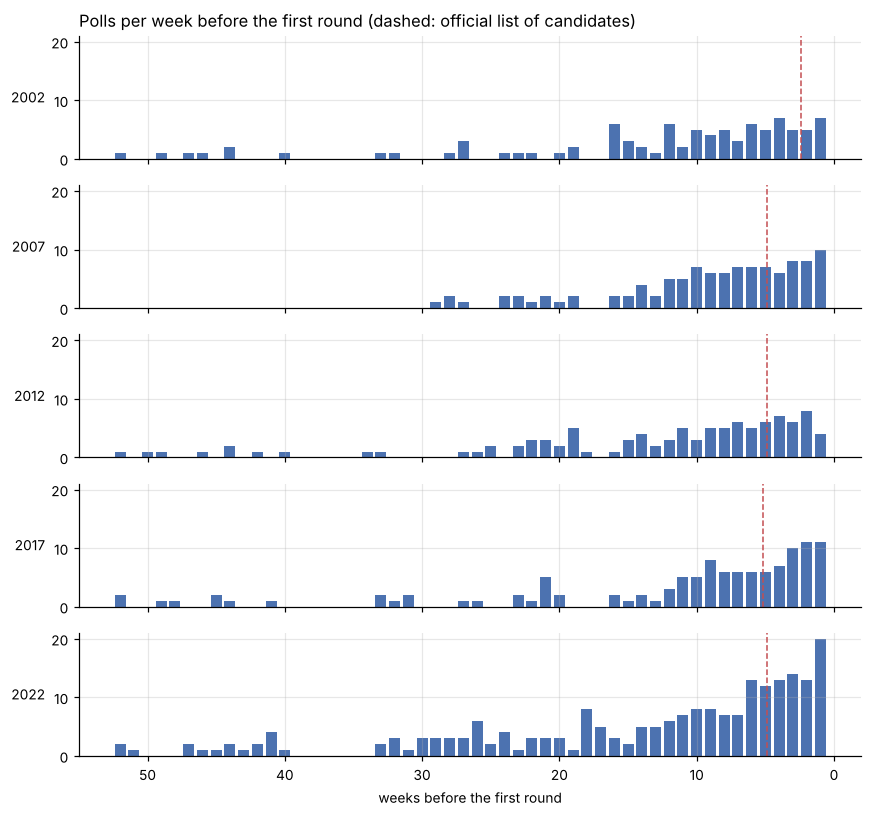

In [4]:
weekly = (polls[polls["weeks_before"] <= 52].groupby(["election", "weeks_before"]).size()
          .unstack("election").reindex(range(1, 53), fill_value=0).fillna(0).astype(int))
weekly.to_csv(TABLES / "coverage_polls_per_week.csv")

fig, axes = plt.subplots(len(ELECTIONS), 1, figsize=(8, 7.5), sharex=True, sharey=True)
for ax, e in zip(axes, ELECTIONS):
    ax.bar(weekly.index, weekly[e], width=0.8, color="#4c72b0")
    lst = (calendar.loc[e, "first_round"] - calendar.loc[e, "official_list"]).days / 7
    ax.axvline(lst, color="#c44e52", lw=1, ls="--")
    ax.set_ylabel(str(e), rotation=0, ha="right", va="center")
axes[0].set_title("Polls per week before the first round (dashed: official list of candidates)", loc="left")
axes[-1].set_xlabel("weeks before the first round")
axes[-1].invert_xaxis()
fig.tight_layout()
fig.savefig(FIGURES / "coverage_polls_per_week.png")
print("share of each election's polls in the last 4 and 8 weeks:")
pd.DataFrame({w: polls[polls["weeks_before"] <= w].groupby("election").size() / polls.groupby("election").size()
              for w in (4, 8)}).round(2)

### Sample sizes (2017 and 2022)

The base of respondents giving a voting intention, as Wikipedia gives it. Absent before 2017.

In [5]:
n = polls.dropna(subset=["sample_size"])
samples = n.groupby("election")["sample_size"].describe(percentiles=[0.1, 0.5, 0.9])[["count", "min", "10%", "50%", "90%", "max"]]
samples["rolling_median"] = n[n["rolling"]].groupby("election")["sample_size"].median()
samples["one_off_median"] = n[~n["rolling"]].groupby("election")["sample_size"].median()
samples.to_csv(TABLES / "coverage_sample_sizes.csv")
samples.round(0)

,count,min,10%,50%,90%,max,rolling_median,one_off_median
election,,,,,,,,
2017,147.0,586.0,926.0,1401.0,5696.0,21326.0,NaN,1401.0
2022,230.0,893.0,1005.0,1502.0,2600.0,16228.0,1578.0,1483.0


### Candidates tested in the ballot scenario

How many candidates a poll offers, against how many were on the ballot. In 2007 and 2012, Wikipedia leaves out
small candidates in many polls (see the spot check).

In [6]:
on_ballot = rows.groupby("election")["slot"].apply(lambda s: s.dropna().nunique())
cands = polls[polls["has_ballot_scenario"]].groupby(["election", "phase"], observed=True)["n_candidates_ballot"].median().unstack()
cands.insert(0, "on_ballot", on_ballot)
cands.to_csv(TABLES / "coverage_candidates_tested.csv")
cands

phase,on_ballot,before the official list,official list to two weeks before,last two weeks
election,,,,
2002,16,16.0,16.0,16.0
2007,12,11.0,12.0,12.0
2012,10,10.0,10.0,10.0
2017,11,9.0,11.0,11.0
2022,12,14.0,12.0,12.0


## 2 · Trajectories

Each poll's ballot scenario gives one share per final candidacy (its `slot`: the candidate, or whoever stands in for
them, e.g. Juppé for Fillon). The poll average is a Gaussian kernel mean of the polls (bandwidth 10 days; where fewer
than 3 polls are nearby, the window widens to the 4th-nearest poll and the line is drawn pale); the band is the spread of the polls around it (± 1 SD). Shares as published (raw); below-threshold
shares at half their bound. The six candidates with the best results are drawn, coloured from left (red) to right (blue) in the order of
Wikipedia's poll-table columns; the dot at 0 is the result.

Markers: **takeovers** (dotted: from this poll on, the ballot scenarios test the final candidate in person, after
others had filled their slot, e.g. Fillon after Juppé and Sarkozy; this can precede the official nomination, since a
poll's scenario with the final candidate is preferred) and **withdrawals** (dashed: the last poll testing a candidate
who will not be on the ballot, if they still polled 1% or more in their last month). Withdrawals change the set of
candidates offered, and with it the concentration of the poll, without any voter changing their mind.

In [7]:
results = pd.read_csv(ROOT / "data" / "interim" / "results.csv")
b = ballot.copy()
b["value"] = np.where(b["share_status"] == "value", b["share"], b["share_upper_bound"] * 0.5)
slot_polls = b.dropna(subset=["slot"]).groupby(["election", "poll_id", "slot"], as_index=False).agg(
    value=("value", "sum"), days_before=("days_before", "first"))

GRID = np.arange(0, 366, 2)
traj = pd.concat([average.by_candidate(g, "value", GRID).assign(election=e)
                  for e, g in slot_polls.groupby("election")], ignore_index=True)
# for drawing only: the window widens where polls are sparse (dashed); statistics use `traj`
traj_draw = pd.concat([average.by_candidate(g, "value", GRID, adaptive_k=4).assign(election=e)
                       for e, g in slot_polls.groupby("election")], ignore_index=True)
traj_dense = traj
weekly_traj = traj[traj["days_before"] % 14 == 0]          # every two weeks, for the committed table
weekly_traj.round(2).to_csv(TABLES / "trajectories_poll_average.csv", index=False)

top6 = results.sort_values("share", ascending=False).groupby("election").head(6)

# takeovers: the final candidate takes over a slot filled by others before
stood_in = b[b["slot"].notna() & (b["candidate"] != b["slot"])].groupby(["election", "slot"])["days_before"].min()
in_person = b[b["candidate"] == b["slot"]]
takeovers = []
for (e, slot), last_stand_in in stood_in.items():
    after = in_person[(in_person["election"] == e) & (in_person["slot"] == slot) & (in_person["days_before"] < last_stand_in)]
    if len(after):
        takeovers.append(dict(election=e, candidate=slot, days_before=after["days_before"].max(), kind="takeover"))
takeovers = pd.DataFrame(takeovers).query("days_before <= 365")
# withdrawals: last poll of a candidate who will not be on the ballot
extra = b[b["slot"].isna()]
last = extra.sort_values("days_before").groupby(["election", "candidate"]).agg(
    days_before=("days_before", "min"), polls=("poll_id", "nunique"))
recent = extra.merge(last["days_before"].rename("last").reset_index()).query("days_before <= last + 30")
last["share_last_month"] = recent.groupby(["election", "candidate"])["share"].mean()
withdrawals = (last[(last["share_last_month"] >= 1) & (last["polls"] >= 3)].reset_index()
               .query("days_before <= 365").assign(kind="withdrawal"))
events = pd.concat([takeovers, withdrawals])[["election", "kind", "candidate", "days_before", "share_last_month"]]
events.round(1).sort_values(["election", "days_before"], ascending=[True, False]).to_csv(TABLES / "trajectories_entries_withdrawals.csv", index=False)
events.sort_values(["election", "days_before"], ascending=[True, False])

,election,kind,candidate,days_before,share_last_month
0,2002,withdrawal,Charles Pasqua,22,2.270833
0,2007,takeover,Dominique Voynet,199,NaN
1,2007,takeover,Ségolène Royal,199,NaN
3,2012,takeover,François Hollande,344,NaN
2,2012,takeover,Eva Joly,304,NaN
4,2012,takeover,Philippe Poutou,232,NaN
2,2012,withdrawal,Jean-Louis Borloo,230,7.000000
1,2012,withdrawal,Dominique de Villepin,83,2.000000
3,2017,withdrawal,Cécile Duflot,189,2.500000
6,2017,takeover,François Fillon,157,NaN


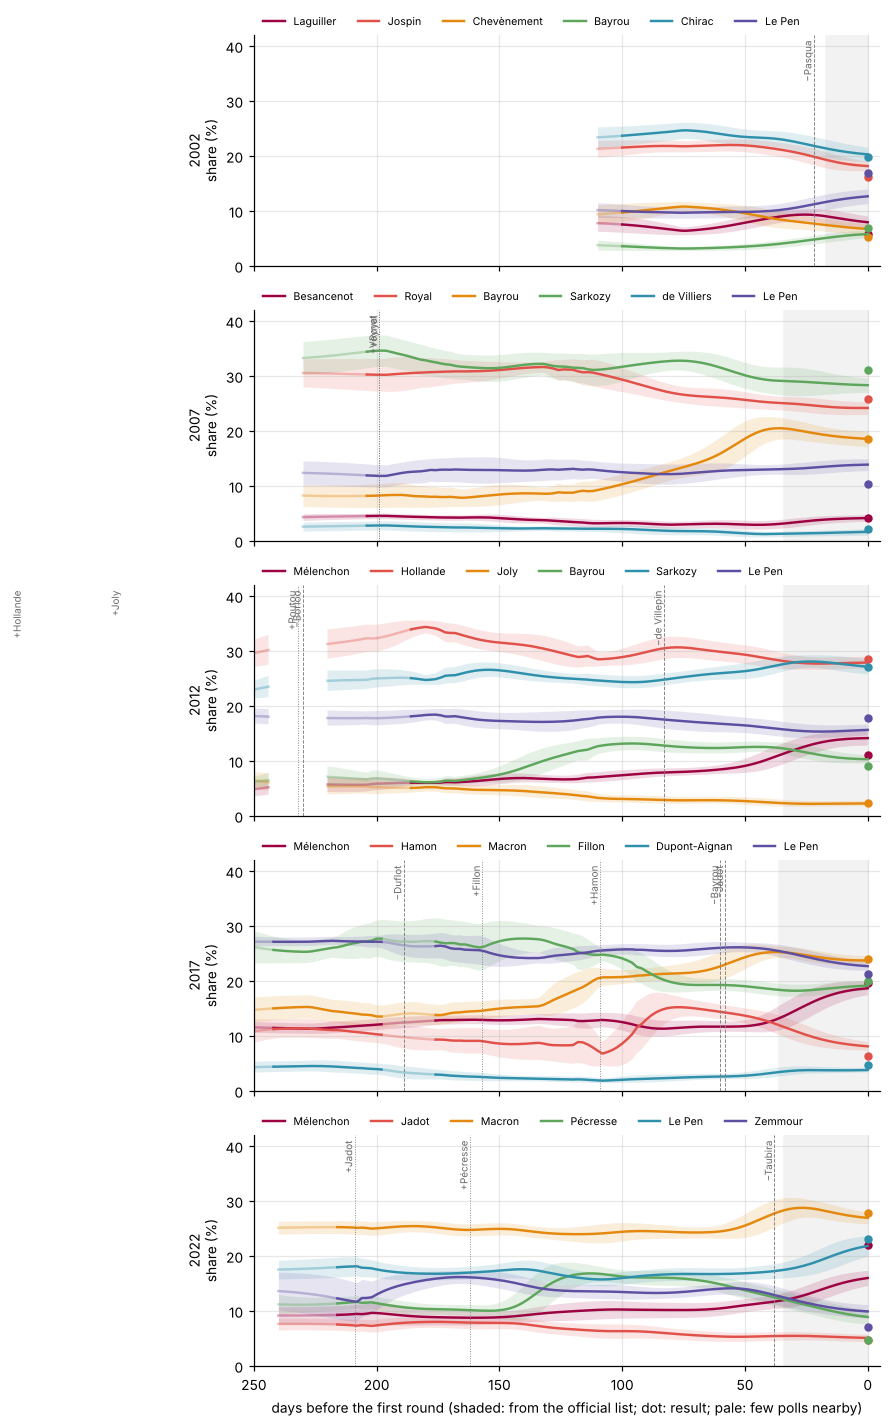

In [8]:
# left-right order of Wikipedia's poll-table columns, coloured with the Spectral colormap (red left, blue right)
lr = ideology.order(ROOT, {int(p.name[:4]): p for p in (ROOT / "data" / "raw" / "wikipedia").glob("*.json")},
                    pd.read_csv(ROOT / "data" / "interim" / "polls_wikipedia.csv", low_memory=False))
lr_pos = lr.set_index(["election", "candidate"])["position"]
def shown_left_to_right(e):
    c = top6[top6["election"] == e]["candidate"].tolist()
    return sorted(c, key=lambda x: lr_pos.get((e, x), 0.5))
surname = lambda name: name.split(" ", 1)[1] if " " in name else name
fig, axes = plt.subplots(len(ELECTIONS), 1, figsize=(8.5, 13), sharex=True)
for ax, e in zip(axes, ELECTIONS):
    order_e = shown_left_to_right(e)
    col = ideology.colours(order_e)
    res = results[results["election"] == e].set_index("candidate")["share"]
    for c in order_e:
        t = traj_draw[(traj_draw["election"] == e) & (traj_draw["slot"] == c)]
        figures.line(ax, t["days_before"], t["mean"], t["sparse"], color=col[c], lw=1.6, label=surname(c))
        ax.fill_between(t["days_before"], t["mean"] - t["sd"], t["mean"] + t["sd"], color=col[c], alpha=0.15, lw=0)
        ax.plot(0, res[c], "o", color=col[c], ms=4.5)
    for r in events[events["election"] == e].itertuples():
        ax.axvline(r.days_before, color="grey", lw=0.6, ls=":" if r.kind == "takeover" else "--")
        ax.text(r.days_before, ax.get_ylim()[1] if False else 41, ("+" if r.kind == "takeover" else "−") + surname(r.candidate),
                rotation=90, fontsize=6.5, va="top", ha="right", color="dimgrey")
    lst = (calendar.loc[e, "first_round"] - calendar.loc[e, "official_list"]).days
    ax.axvspan(0, lst, color="#f2f2f2", zorder=0)
    ax.set_ylim(0, 42)
    ax.set_ylabel(f"{e}\nshare (%)")
    ax.legend(loc="upper left", fontsize=7, ncol=6, frameon=False, bbox_to_anchor=(0, 1.13))
axes[-1].set_xlim(250, -5)
axes[-1].set_xlabel("days before the first round (shaded: from the official list; dot: result; pale: few polls nearby)")
fig.tight_layout()
fig.savefig(FIGURES / "trajectories.png")

### Volatility

How much the poll average moves from one week to the next: mean absolute change over seven days, averaged over the
six leading candidates, by phase. Movement of the average, not of single polls.

In [9]:
t7 = traj_dense[traj_dense["days_before"] % 7 == 0].sort_values("days_before")
t7 = t7.merge(top6[["election", "candidate"]].rename(columns={"candidate": "slot"}))
t7["weekly_change"] = t7.groupby(["election", "slot"])["mean"].diff().abs()
t7 = timeline.add_time(t7.assign(date=lambda d: d["election"].map(calendar["first_round"]) - pd.to_timedelta(d["days_before"], "D")), calendar)
volatility = t7.groupby(["election", "phase"], observed=True)["weekly_change"].mean().unstack().round(2)
volatility["last 12 months"] = t7[t7["days_before"] <= 365].groupby("election")["weekly_change"].mean().round(2)
volatility.to_csv(TABLES / "trajectories_volatility.csv")
volatility

phase,before the official list,official list to two weeks before,last two weeks,last 12 months
election,,,,
2002,0.54,NaN,0.74,0.57
2007,0.55,0.51,0.26,0.53
2012,0.63,0.50,0.32,0.59
2017,0.88,1.18,0.55,0.88
2022,0.62,1.31,0.99,0.69


## 3 · Rank stability

Each poll's ballot scenario is ranked (tied candidates share a rank, as in Part 0). Its **top two** is compared with
the real runoff pair: `right pair`, `right pair, tied` (the pair is there but tied with a third candidate), or
`wrong pair`. The same is done on the poll average, day by day, to find when the runoff pair stops changing and how
often 2nd and 3rd swap. Candidates who will not be on the ballot are left out of the ranks (none was above 4th in the
final months).

In [10]:
runoff = results.sort_values("share", ascending=False).groupby("election").head(2)
pair = runoff.groupby("election")["candidate"].apply(frozenset)
ranked = []
for (e, pid), g in slot_polls.groupby(["election", "poll_id"]):
    s = pd.Series(g["value"].to_numpy(), index=g["slot"].to_numpy())
    role = metrics.roles(s)
    top2 = frozenset(role[role.isin(["leader", "2nd"])].index)
    order = s.sort_values(ascending=False).index
    outcome = ("right pair" if top2 == pair[e] else "right pair, tied" if pair[e] <= top2 else "wrong pair")
    ranked.append(dict(election=e, poll_id=pid, days_before=g["days_before"].iloc[0],
                       first=order[0], second=order[1], third=order[2], fourth=order[3] if len(order) > 3 else None,
                       right_leader=role.get(runoff[runoff["election"] == e]["candidate"].iloc[0]) == "leader",
                       top2=outcome))
ranked = timeline.add_time(pd.DataFrame(ranked).assign(
    date=lambda d: d["election"].map(calendar["first_round"]) - pd.to_timedelta(d["days_before"], "D")), calendar)
ranked.drop(columns=["date"]).to_csv(TABLES / "ranks_by_poll.csv", index=False)

right = (ranked.assign(right=ranked["top2"] == "right pair")
         .groupby(["election", "phase"], observed=True)["right"].mean().unstack().round(2))
right["all ballot polls"] = ranked.groupby("election")["top2"].apply(lambda x: (x == "right pair").mean()).round(2)
right["1st place right, last two weeks"] = (ranked[ranked["phase"] == timeline.PHASES[2]]
                                          .groupby("election")["right_leader"].mean().round(2))
right.to_csv(TABLES / "ranks_right_pair_by_phase.csv")
print("Share of polls whose top two is the real runoff pair:")
right

Share of polls whose top two is the real runoff pair:


phase,before the official list,official list to two weeks before,last two weeks,all ballot polls,"1st place right, last two weeks"
election,,,,,
2002,0.00,0.0,0.00,0.00,1.00
2007,0.99,1.0,1.00,0.99,1.00
2012,0.94,1.0,1.00,0.96,0.67
2017,0.52,1.0,0.95,0.71,0.91
2022,0.57,1.0,1.00,0.73,1.00


In [11]:
print("Outcome of the last 10 polls of each election:")
last10 = ranked.sort_values("days_before").groupby("election").head(10)
pd.crosstab(last10["election"], last10["top2"])

Outcome of the last 10 polls of each election:


top2,right pair,wrong pair
election,,
2002,0,10
2007,10,0
2012,10,0
2017,10,0
2022,10,0


### On the poll average

Daily ranks of the poll average (last 365 days, where it exists). **Locked from**: the last day on which the average's
top two differed from the runoff pair; from then on it is right every day. Empty when the average never has the
right pair at the end (2002). **Top-two changes**: how many times the set of the two leading candidates changed
(someone crossed the cliff); **leader changes**: how many times 1st place changed hands; over the last year and the
last 60 days.

In [12]:
avg = traj_dense.dropna(subset=["mean"]).copy()
avg["rank"] = avg.groupby(["election", "days_before"])["mean"].rank(ascending=False, method="first")
# for drawing: every day of the widened average
avg_all = traj_draw.dropna(subset=["mean"]).copy()
avg_all["rank"] = avg_all.groupby(["election", "days_before"])["mean"].rank(ascending=False, method="first")
daily = avg.pivot_table(index=["election", "days_before"], columns="rank", values="slot", aggfunc="first")
daily = daily[[1.0, 2.0, 3.0, 4.0]].rename(columns=lambda r: f"rank_{int(r)}").reset_index()
daily["right_pair"] = [frozenset((a, b)) == pair[e] for e, a, b in zip(daily["election"], daily["rank_1"], daily["rank_2"])]

def changes(d, cols):
    key = d[cols].apply(frozenset, axis=1)
    return int((key != key.shift()).iloc[1:].sum())

def summary(g):
    g = g.sort_values("days_before", ascending=False)
    wrong = g.loc[~g["right_pair"], "days_before"]
    locked = (np.nan if g["right_pair"].iloc[-1] is False or not g["right_pair"].iloc[-1]
              else int(wrong.min()) - 2 if len(wrong) else g["days_before"].max())
    last60 = g[g["days_before"] <= 60]
    return pd.Series({"first_day_with_average": g["days_before"].max(),
                      "share_of_days_right": round(g["right_pair"].mean(), 2),
                      "locked_from_days_before": locked,
                      "top_two_changes_last_year": changes(g, ["rank_1", "rank_2"]),
                      "top_two_changes_last_60_days": changes(last60, ["rank_1", "rank_2"]),
                      "leader_changes_last_year": changes(g, ["rank_1"]),
                      "leader_changes_last_60_days": changes(last60, ["rank_1"])})
lockin = daily.groupby("election").apply(summary, include_groups=False)
lockin["last_wrong_poll_days_before"] = ranked[ranked["top2"] != "right pair"].groupby("election")["days_before"].min()
lockin.to_csv(TABLES / "ranks_lockin.csv")
lockin

,first_day_with_average,share_of_days_right,locked_from_days_before,top_two_changes_last_year,top_two_changes_last_60_days,leader_changes_last_year,leader_changes_last_60_days,last_wrong_poll_days_before
election,,,,,,,,
2002,100.0,0.00,NaN,0.0,0.0,0.0,0.0,3
2007,204.0,1.00,204.0,0.0,0.0,0.0,0.0,44
2012,208.0,1.00,208.0,0.0,0.0,2.0,2.0,381
2017,242.0,0.39,86.0,1.0,0.0,5.0,1.0,8
2022,216.0,0.88,96.0,2.0,0.0,0.0,0.0,35


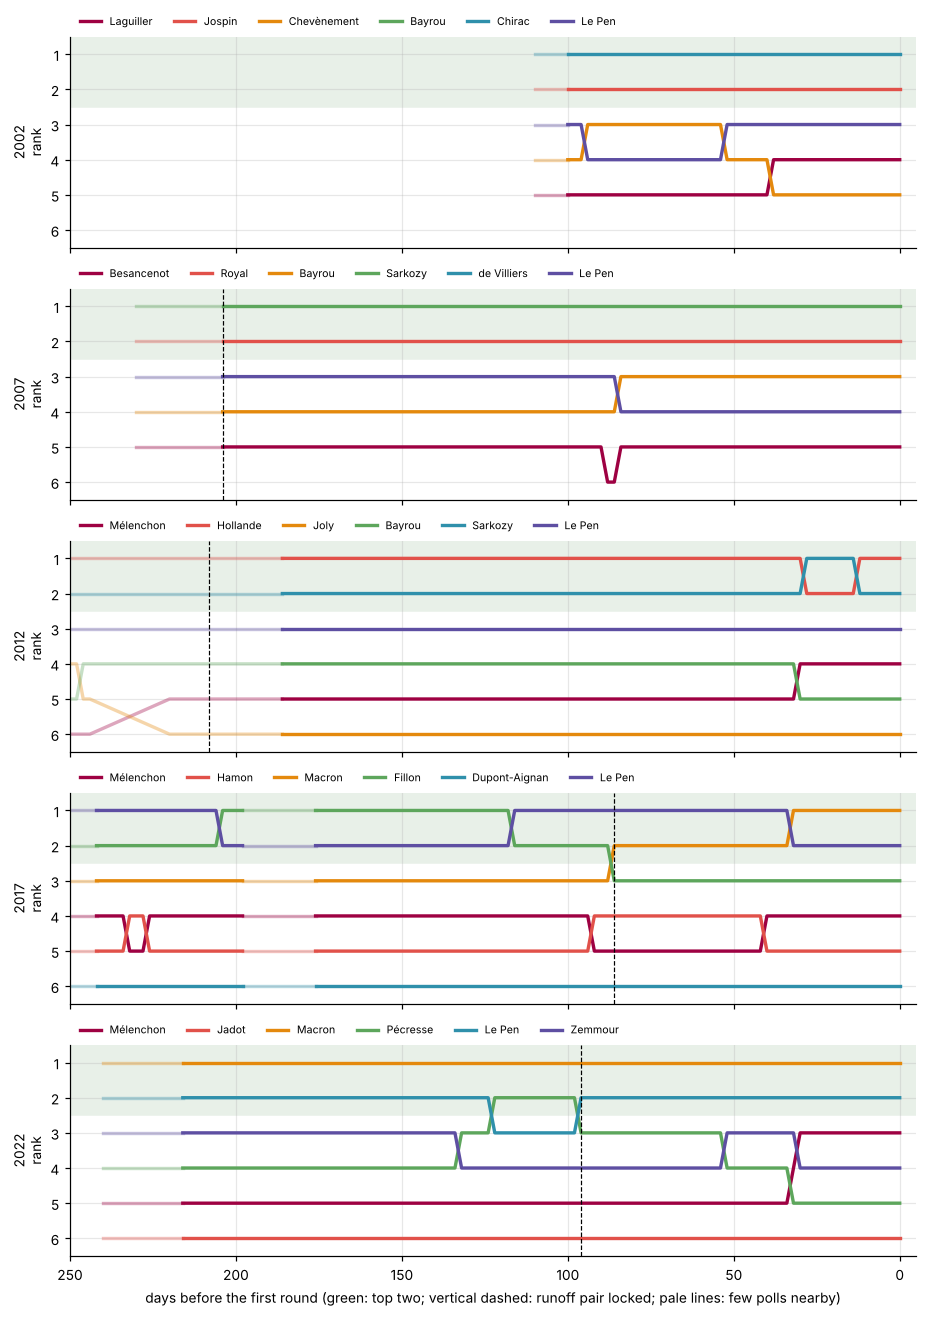

In [13]:
fig, axes = plt.subplots(len(ELECTIONS), 1, figsize=(8.5, 12), sharex=True)
for ax, e in zip(axes, ELECTIONS):
    a = avg_all[avg_all["election"] == e]
    shown = shown_left_to_right(e)
    col = ideology.colours(shown)
    for c in shown:
        t = a[a["slot"] == c].sort_values("days_before")
        figures.line(ax, t["days_before"], t["rank"], t["sparse"], color=col[c], lw=2.2, label=surname(c))
    ax.axhspan(0.5, 2.5, color="#e8f0e8", zorder=0)
    lk = lockin.loc[e, "locked_from_days_before"]
    if pd.notna(lk):
        ax.axvline(lk, color="black", lw=0.8, ls="--")
    ax.set_ylim(6.5, 0.5); ax.set_yticks(range(1, 7))
    ax.set_ylabel(f"{e}\nrank")
    ax.legend(loc="upper left", fontsize=7, ncol=6, frameon=False, bbox_to_anchor=(0, 1.15))
axes[-1].set_xlim(250, -5)
axes[-1].set_xlabel("days before the first round (green: top two; vertical dashed: runoff pair locked; pale lines: few polls nearby)")
fig.tight_layout()
fig.savefig(FIGURES / "ranks.png")

## 4 · Pollsters

**Residuals.** Each poll's share for a candidate minus the poll average of the *other* polls around its date
(leave-one-out, same kernel as above), so a poll does not pull the average toward itself.

**House effects.** A pollster's mean residual for a candidate, over its polls in that election (pollster families;
at least 5 polls). Starred when the mean is at least twice its standard error. The six leading candidates.

In [14]:
res = slot_polls.merge(polls[["poll_id", "institute_family", "sample_size", "phase"]], on="poll_id")
res["loo"] = np.nan
for (e, s), g in res.groupby(["election", "slot"]):
    res.loc[g.index, "loo"] = average.leave_one_out(g["days_before"].to_numpy(), g["value"].to_numpy())
res["residual"] = res["value"] - res["loo"]
main = res.merge(top6[["election", "candidate"]].rename(columns={"candidate": "slot"})).dropna(subset=["residual"])

house = main.groupby(["election", "institute_family", "slot"])["residual"].agg(["size", "mean", "std"]).reset_index()
house = house.rename(columns={"size": "polls", "mean": "house_effect"})
house["se"] = house["std"] / np.sqrt(house["polls"])
house["significant"] = (house["house_effect"].abs() >= 2 * house["se"]) & (house["polls"] >= 5)
house = house[house["polls"] >= 5].drop(columns="std")
house.round(2).to_csv(TABLES / "pollsters_house_effects.csv", index=False)
print("Largest house effects (|effect| >= 1.5 points, significant):")
house[house["significant"] & (house["house_effect"].abs() >= 1.5)].sort_values("house_effect").round(2)

Largest house effects (|effect| >= 1.5 points, significant):


,election,institute_family,slot,polls,house_effect,se,significant
44,2007,CSA,Nicolas Sarkozy,20,-2.06,0.33,True
86,2012,Harris Interactive,François Hollande,9,-1.94,0.31,True
112,2012,LH2 (Louis Harris),Marine Le Pen,9,-1.92,0.38,True
192,2022,Cluster17,Emmanuel Macron,17,-1.65,0.23,True
194,2022,Cluster17,Marine Le Pen,17,-1.63,0.21,True
230,2022,Odoxa,Marine Le Pen,5,1.55,0.31,True
88,2012,Harris Interactive,Marine Le Pen,9,1.75,0.32,True
56,2007,Ipsos,Nicolas Sarkozy,25,1.76,0.22,True
74,2012,BVA,François Hollande,12,1.87,0.50,True
43,2007,CSA,Jean-Marie Le Pen,20,2.16,0.28,True


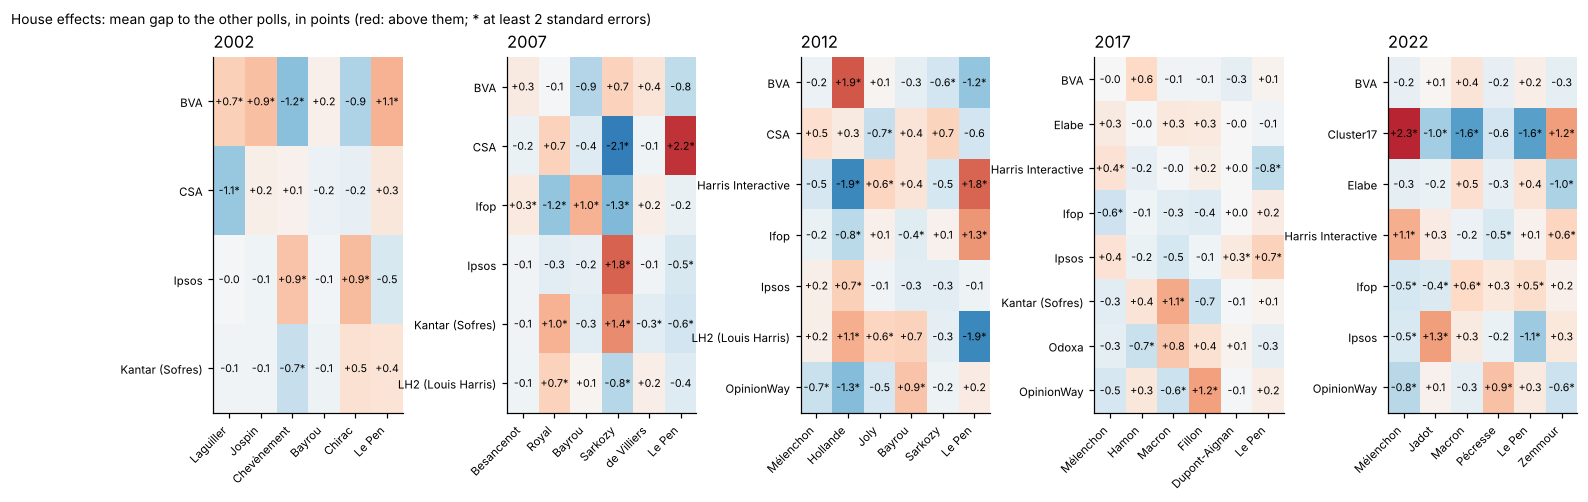

In [15]:
fig, axes = plt.subplots(1, len(ELECTIONS), figsize=(16, 4.2), gridspec_kw={"wspace": 0.55})
for ax, e in zip(axes, ELECTIONS):
    cands = shown_left_to_right(e)
    h = house[house["election"] == e]
    firms = h.groupby("institute_family")["polls"].max().loc[lambda x: x >= 8].index
    m = h.pivot(index="institute_family", columns="slot", values="house_effect").reindex(index=firms, columns=cands)
    sig = h.pivot(index="institute_family", columns="slot", values="significant").reindex(index=firms, columns=cands)
    ax.imshow(m.to_numpy(dtype=float), cmap="RdBu_r", vmin=-3, vmax=3, aspect="auto")
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            v = m.iat[i, j]
            if pd.notna(v):
                ax.text(j, i, f"{v:+.1f}" + ("*" if sig.iat[i, j] else ""), ha="center", va="center", fontsize=7)
    ax.set_xticks(range(len(cands)), [surname(c) for c in cands], rotation=45, ha="right", fontsize=7.5)
    ax.set_yticks(range(len(firms)), firms, fontsize=7.5)
    ax.set_title(str(e), loc="left"); ax.grid(False)
fig.suptitle("House effects: mean gap to the other polls, in points (red: above them; * at least 2 standard errors)",
             x=0.01, ha="left", fontsize=9)
fig.savefig(FIGURES / "pollsters_house_effects.png", bbox_inches="tight")

### Herding

How much polls scatter around the average, against how much sampling alone would make them scatter. Expected sampling
variance of a share *p* with *n* respondents: *p*(1 − *p*)/*n*; *n* is the poll's base where Wikipedia gives it
(2017, 2022), otherwise 1,000 (assumed). The **ratio** is observed / expected variance, over the six leading candidates:

- above 1: more scatter than sampling (pollsters differ, or opinion moves within the averaging window);
- below 1: less scatter than sampling allows, the signature of herding.

The observed scatter also contains real movement within the ±10-day window, which inflates the ratio, so a ratio
below 1 is strong evidence of herding while a ratio above 1 does not rule it out. *After house effects*: residuals minus
each pollster's house effect for that candidate.

In [16]:
main = main.merge(house[["election", "institute_family", "slot", "house_effect"]], how="left")
main["n"] = main["sample_size"].fillna(1000)
main["expected_var"] = main["value"] * (100 - main["value"]) / main["n"]
main["resid_net"] = main["residual"] - main["house_effect"].fillna(0)

def ratio(g, col):
    return (g[col] ** 2).mean() / g["expected_var"].mean()
herd = pd.DataFrame({
    "polls": main.groupby(["election", "phase"], observed=True)["poll_id"].nunique(),
    "ratio": main.groupby(["election", "phase"], observed=True).apply(ratio, "residual", include_groups=False),
    "ratio_after_house_effects": main.groupby(["election", "phase"], observed=True).apply(ratio, "resid_net", include_groups=False),
}).round(2)
herd.to_csv(TABLES / "pollsters_herding.csv")
herd.unstack("phase")

polls                                                                     ratio                                                  ratio_after_house_effects  \
phase    before the official list official list to two weeks before last two weeks before the official list official list to two weeks before last two weeks  before the official list   
election                                                                                                                                                                                 
2002                           32                                 5             12                     1.16                              1.15           1.07                      0.73   
2007                           67                                20             18                     2.34                              1.96           1.00                      1.64   
2012                           69                                17             12                     1.41                              0.89           0.93                      0.81   
2017                           60                                23             22                     2.57                              1.03           0.73                      2.29   
2022                          113                                37             33                     2.30                              1.47           1.96                      1.38   

                                                           
phase    official list to two weeks before last two weeks  
election                                                   
2002                                  0.89           0.64  
2007                                  1.21           0.70  
2012                                  0.64           0.87  
2017                                  0.99           0.69  
2022                                  1.12           1.85

## 5 · Noise

**Effective sample size**: the size of a simple random sample that would scatter around the poll average as much as
the real polls do, *n*<sub>eff</sub> = mean *p*(1 − *p*) / mean squared residual, over the six leading candidates of
the ballot polls. Computed on the raw residuals (what a voter reading any one poll faces) and after removing house
effects (pure noise). For 2017 and 2022 it is compared with the polls' own base (median), whose ratio is a
**design effect** (above 1: polls noisier than their size suggests).

Real movement within the averaging window counts as noise here, so *n*<sub>eff</sub> is a lower bound, most of all
in fast-moving phases. A Dirichlet poll of precision ρ has variance *p*(1 − *p*)/(ρ + 1): ρ ≈ *n*<sub>eff</sub> − 1
(Part 3).

In [17]:
def n_eff(g, col):
    return (g["value"] * (100 - g["value"])).mean() / (g[col] ** 2).mean()

periods = {"last 12 months": main[main["days_before"] <= 365]}
periods.update({str(ph): main[main["phase"] == ph] for ph in timeline.PHASES})
noise = []
for label, d in periods.items():
    for e, g in d.groupby("election"):
        noise.append(dict(election=e, period=label, polls=g["poll_id"].nunique(),
                          n_eff=n_eff(g, "residual"), n_eff_after_house_effects=n_eff(g, "resid_net"),
                          median_base=g.drop_duplicates("poll_id")["sample_size"].median()))
noise = pd.DataFrame(noise)
noise["design_effect"] = noise["median_base"] / noise["n_eff"]
noise.round(2).to_csv(TABLES / "noise_effective_sample_size.csv", index=False)
noise.pivot(index="election", columns="period", values="n_eff")[["last 12 months"] + timeline.PHASES].round(0)

period,last 12 months,before the official list,official list to two weeks before,last two weeks
election,,,,
2002,877.0,860.0,866.0,935.0
2007,492.0,427.0,509.0,1004.0
2012,844.0,712.0,1125.0,1073.0
2017,753.0,538.0,1393.0,1814.0
2022,781.0,706.0,993.0,891.0


In [18]:
print("After house effects:")
noise.pivot(index="election", columns="period", values="n_eff_after_house_effects")[["last 12 months"] + timeline.PHASES].round(0)

After house effects:


period,last 12 months,before the official list,official list to two weeks before,last two weeks
election,,,,
2002,1382.0,1372.0,1122.0,1571.0
2007,717.0,609.0,826.0,1421.0
2012,1354.0,1229.0,1561.0,1143.0
2017,831.0,603.0,1451.0,1932.0
2022,1146.0,1175.0,1301.0,942.0


In [19]:
print("2017 and 2022: polls' median base against their effective sample size")
noise.dropna(subset=["median_base"]).pivot(index="election", columns="period", values="design_effect")[["last 12 months"] + timeline.PHASES].round(2)

2017 and 2022: polls' median base against their effective sample size


period,last 12 months,before the official list,official list to two weeks before,last two weeks
election,,,,
2017,1.89,2.61,1.08,0.81
2022,1.93,2.13,1.52,2.11
